# Pipeline CNN – Clasificación de tumores cerebrales en resonancias (MRI)
**Dataset:** Brain Tumor MRI (Kaggle, masoudnickparvar) · 4 clases: glioma, meningioma, notumor, pituitary

## Parte 1 · Configuración, carga de datos y verificación
Contenido: entorno de Colab, carga del zip desde Drive, estructura de carpetas, conteo por clase, revisión de calidad (tamaños, canales y duplicados).

### 1.1 Entorno y GPU
Antes de ejecutar: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*.

In [ ]:
import os, sys, random, hashlib, zipfile, shutil, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU        :", gpus if gpus else "NO DETECTADA (el entrenamiento será muy lento)")

Python     : 3.13.16
TensorFlow : 2.21.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 1.2 Cargar el dataset
Sube `archive.zip` al espacio de archivos de Colab (panel izquierdo, carpeta `/content`) y ejecuta la celda.

In [ ]:
ZIP_PATH = "/content/archive.zip"
DATA_DIR = "/content/data"          # copia local descomprimida

assert os.path.exists(ZIP_PATH), f"No se encontró el zip en: {ZIP_PATH}"

if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    print("Descomprimido en", DATA_DIR)
else:
    print("Ya existe", DATA_DIR, "- se reutiliza")

TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR  = os.path.join(DATA_DIR, "Testing")
print(os.listdir(DATA_DIR))

Ya existe /content/data - se reutiliza
['Training', 'Testing']


### 1.3 Estructura y conteo por clase

Clases: ['glioma', 'meningioma', 'notumor', 'pituitary']


split,Testing,Training,Total
clase,,,
glioma,400,1400,1800
meningioma,400,1400,1800
notumor,400,1400,1800
pituitary,400,1400,1800
TOTAL,1600,5600,7200


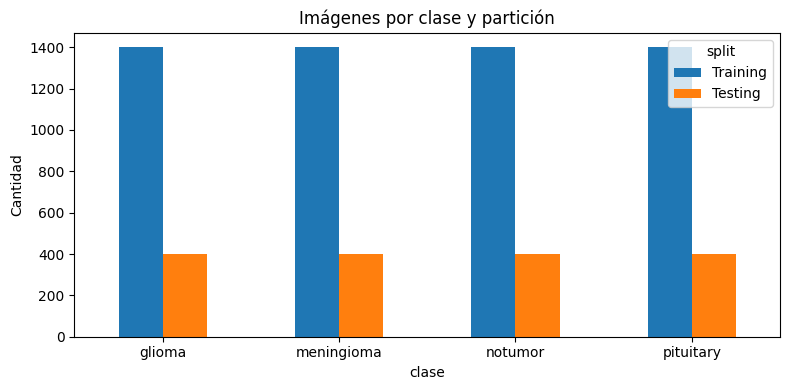

In [ ]:
CLASSES = sorted(os.listdir(TRAIN_DIR))
print("Clases:", CLASSES)

rows = []
for split, path in [("Training", TRAIN_DIR), ("Testing", TEST_DIR)]:
    for c in CLASSES:
        n = len([f for f in os.listdir(os.path.join(path, c)) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
        rows.append({"split": split, "clase": c, "imagenes": n})

df_count = pd.DataFrame(rows).pivot(index="clase", columns="split", values="imagenes")
df_count["Total"] = df_count.sum(axis=1)
df_count.loc["TOTAL"] = df_count.sum()
display(df_count)

df_count.drop("TOTAL")[["Training", "Testing"]].plot(kind="bar", figsize=(8, 4))
plt.title("Imágenes por clase y partición"); plt.ylabel("Cantidad"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1.4 Revisión de calidad: tamaños, canales y duplicados exactos
El dataset mezcla imágenes de distintos tamaños y modos de color, y puede traer archivos repetidos. Esto se debe resolver **antes** de dividir en train/validación.

In [ ]:
sizes, modes = collections.Counter(), collections.Counter()
hash_to_path, duplicates = {}, []   # duplicates: copias que se pueden eliminar

for split, path in [("Training", TRAIN_DIR), ("Testing", TEST_DIR)]:
    for c in CLASSES:
        folder = os.path.join(path, c)
        for f in sorted(os.listdir(folder)):
            p = os.path.join(folder, f)
            with Image.open(p) as im:
                sizes[im.size] += 1
                modes[im.mode] += 1
            h = hashlib.md5(open(p, "rb").read()).hexdigest()
            if h in hash_to_path:
                duplicates.append((hash_to_path[h], p))
            else:
                hash_to_path[h] = p

print("Modos de color :", dict(modes))
print("Tamaños distintos:", len(sizes))
print("Más frecuentes :", sizes.most_common(5))

cross = [d for d in duplicates if ("Training" in d[0]) != ("Training" in d[1])]
print(f"\nDuplicados exactos: {len(duplicates)}  |  entre Training y Testing: {len(cross)}")

Modos de color : {'L': 3067, 'RGB': 4129, 'RGBA': 3, 'P': 1}
Tamaños distintos: 447
Más frecuentes : [((512, 512), 5014), ((225, 225), 338), ((630, 630), 90), ((201, 251), 57), ((228, 221), 51)]

Duplicados exactos: 187  |  entre Training y Testing: 0


### 1.5 Muestras por clase

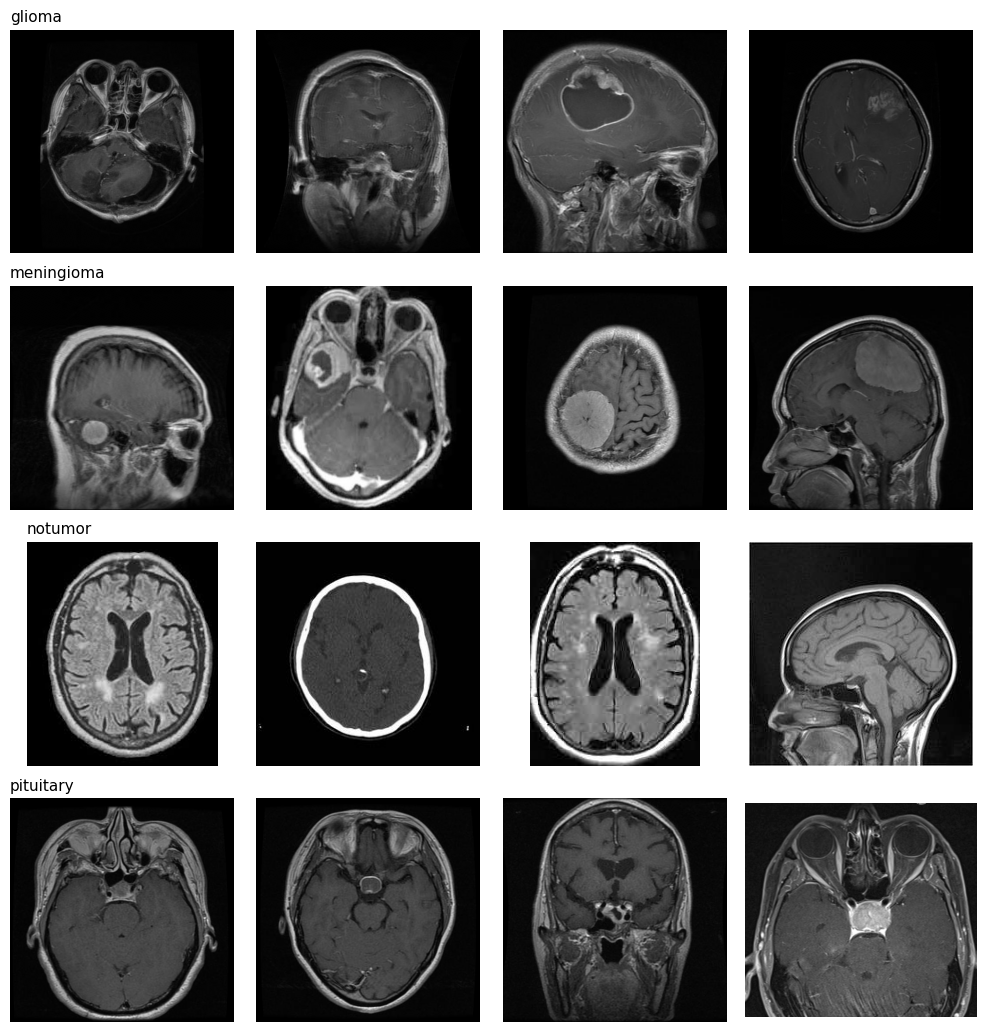

In [ ]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(10, 2.6 * len(CLASSES)))
rng = random.Random(SEED)
for i, c in enumerate(CLASSES):
    files = rng.sample(os.listdir(os.path.join(TRAIN_DIR, c)), 4)
    for j, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img, cmap="gray"); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(c, loc="left", fontsize=11)
plt.tight_layout(); plt.show()

### 1.6 Resumen de la Parte 1
Completa con los resultados de tus celdas anteriores:
- Total de imágenes: 7,200  (Training: 5,600 · Testing: 1,600)
- Clases: 4 · distribución balanceada: sí (1,400 imágenes por clase en Training y 400 por clase en Testing)
- Modos de color encontrados: L (3,067), RGB (4,129), RGBA (3) y P (1) → se unificarán a RGB en la Parte 3
- Duplicados exactos: 187 (se eliminan de Training en la Parte 3, antes de dividir en train/validación)

**Siguiente:** Parte 2 · Definición del problema y EDA

## Parte 2 · Definición del problema y análisis exploratorio (EDA)

**Problema:** clasificar imágenes de resonancia magnética (MRI) cerebral en 4 categorías: glioma, meningioma, pituitary (tumor de hipófisis) y notumor (sin tumor).

**Tipo de tarea:** clasificación de imágenes multiclase (4 clases).

**Métricas:** exactitud (accuracy), precisión, recall y F1 por clase, y matriz de confusión. El recall de las clases con tumor es especialmente importante, porque un falso negativo es el error más costoso.

**Alcance:** proyecto académico. El modelo no sustituye un diagnóstico médico.

tabla de metadatos


In [ ]:
rows = []
for split, base in [("Training", TRAIN_DIR), ("Testing", TEST_DIR)]:
    for c in CLASSES:
        folder = os.path.join(base, c)
        for f in os.listdir(folder):
            p = os.path.join(folder, f)
            with Image.open(p) as im:
                w, h, m = im.size[0], im.size[1], im.mode
            rows.append({"split": split, "clase": c, "archivo": f, "ruta": p,
                         "ancho": w, "alto": h, "modo": m,
                         "kb": os.path.getsize(p) / 1024, "aug": "aug" in f})
df_meta = pd.DataFrame(rows)
df_meta["aspecto"] = df_meta["ancho"] / df_meta["alto"]
df_meta["es_512"] = (df_meta["ancho"] == 512) & (df_meta["alto"] == 512)
df_meta["es_gris"] = df_meta["modo"] == "L"
print(df_meta.shape)
df_meta.head()

(7200, 12)


,split,clase,archivo,ruta,ancho,alto,modo,kb,aug,aspecto,es_512,es_gris
0,Training,glioma,Tr-gl_492.jpg,/content/data/Training/glioma/Tr-gl_492.jpg,512,512,L,16.368164,False,1.0,True,True
1,Training,glioma,Tr-gl_1362.jpg,/content/data/Training/glioma/Tr-gl_1362.jpg,512,512,L,17.984375,False,1.0,True,True
2,Training,glioma,Tr-gl_314.jpg,/content/data/Training/glioma/Tr-gl_314.jpg,512,512,L,14.503906,False,1.0,True,True
3,Training,glioma,Tr-gl_46.jpg,/content/data/Training/glioma/Tr-gl_46.jpg,512,512,L,16.510742,False,1.0,True,True
4,Training,glioma,Tr-gl_788.jpg,/content/data/Training/glioma/Tr-gl_788.jpg,512,512,L,20.198242,False,1.0,True,True


tamaño y color por clase

,pct_512,pct_gris,ancho_mediano,aspecto_medio,kb_mediano
clase,,,,,
glioma,95.8,77.7,512.0,0.998,18.937
meningioma,86.1,39.4,512.0,0.993,21.338
notumor,1.1,1.6,228.0,0.968,12.102
pituitary,95.6,51.7,512.0,1.000,27.657


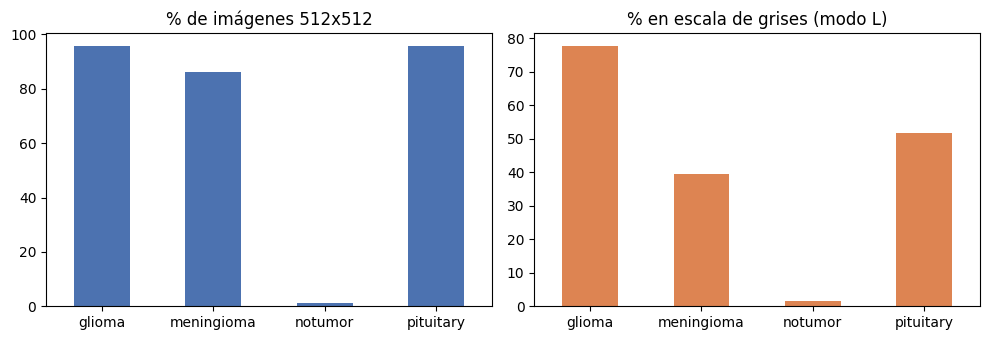

In [ ]:
resumen = df_meta.groupby("clase").agg(
    pct_512=("es_512", "mean"), pct_gris=("es_gris", "mean"),
    ancho_mediano=("ancho", "median"), aspecto_medio=("aspecto", "mean"),
    kb_mediano=("kb", "median")).round(3)
resumen[["pct_512", "pct_gris"]] *= 100
display(resumen)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
resumen["pct_512"].plot(kind="bar", ax=ax[0], color="#4C72B0", title="% de imágenes 512x512")
resumen["pct_gris"].plot(kind="bar", ax=ax[1], color="#DD8452", title="% en escala de grises (modo L)")
for a in ax:
    a.set_xlabel(""); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

brillo y contraste por clase

,brillo_medio,contraste_std
clase,,
glioma,0.128,0.149
meningioma,0.177,0.182
notumor,0.248,0.226
pituitary,0.193,0.158


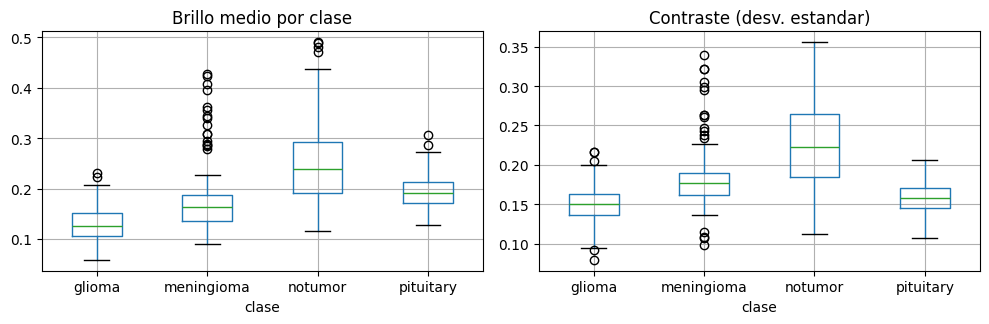

In [ ]:
muestra = df_meta[df_meta["split"] == "Training"].groupby("clase").sample(150, random_state=SEED)
stats, medias = [], {}
for c in CLASSES:
    acum = []
    for p in muestra[muestra["clase"] == c]["ruta"]:
        a = np.asarray(Image.open(p).convert("L").resize((128, 128)), dtype=np.float32) / 255.0
        stats.append({"clase": c, "brillo_medio": a.mean(), "contraste_std": a.std()})
        acum.append(a)
    medias[c] = np.mean(acum, axis=0)
df_int = pd.DataFrame(stats)
display(df_int.groupby("clase").mean().round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df_int.boxplot(column="brillo_medio", by="clase", ax=ax[0]); ax[0].set_title("Brillo medio por clase")
df_int.boxplot(column="contraste_std", by="clase", ax=ax[1]); ax[1].set_title("Contraste (desv. estandar)")
plt.suptitle(""); plt.tight_layout(); plt.show()

imagen promedio por clase

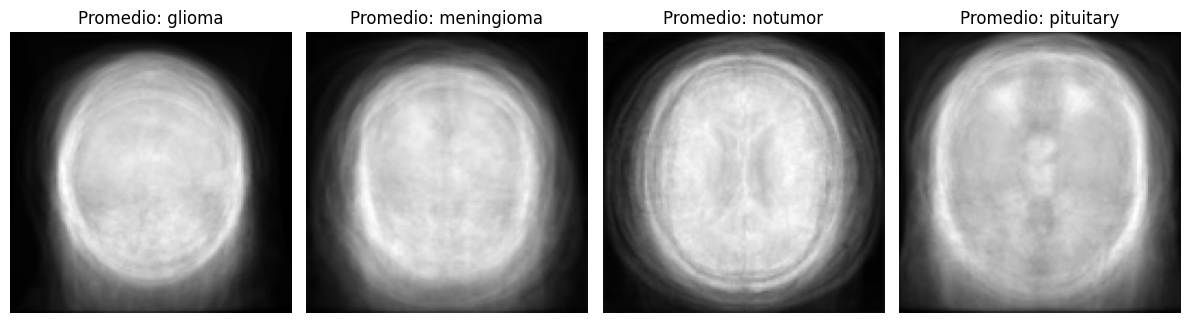

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, c in zip(axes, CLASSES):
    ax.imshow(medias[c], cmap="gray"); ax.set_title(f"Promedio: {c}"); ax.axis("off")
plt.tight_layout(); plt.show()

duplicados e imágenes aumentadas por clase

In [ ]:
dup_por_clase = collections.Counter(os.path.normpath(copia).split(os.sep)[-2] for _, copia in duplicates)
aug_por_clase = df_meta[df_meta["aug"]].groupby("clase").size()
df_extra = pd.DataFrame({"duplicados": pd.Series(dup_por_clase),
                         "aumentadas (aug)": aug_por_clase}).reindex(CLASSES).fillna(0).astype(int)
display(df_extra)

,duplicados,aumentadas (aug)
glioma,14,0
meningioma,16,203
notumor,119,0
pituitary,38,0


¿cuánto se puede adivinar sin mirar los píxeles?

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

feat = ["ancho", "alto", "kb", "es_gris"]          # solo metadatos del archivo, SIN mirar los pixeles
tr = df_meta[df_meta["split"] == "Training"]
te = df_meta[df_meta["split"] == "Testing"]
rf = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(tr[feat], tr["clase"])
acc = accuracy_score(te["clase"], rf.predict(te[feat]))
print(f"Exactitud en Testing usando SOLO metadatos: {acc:.3f}  (azar = 0.250)")

Exactitud en Testing usando SOLO metadatos: 0.614  (azar = 0.250)


### Conclusiones del EDA
- Dataset balanceado: 1,400 imágenes por clase en Training y 400 en Testing.
- Heterogeneidad: 447 tamaños distintos y modos de color mezclados (L, RGB, RGBA, P). Se unificarán en la Parte 3.
- Las clases difieren en tamaño, color y brillo (notumor casi nunca es 512x512; glioma es mayormente gris).
- Un modelo que usa solo metadatos del archivo alcanza 0.614 de exactitud (azar = 0.25), lo que indica posibles sesgos de adquisición.
- Duplicados exactos: 187 (concentrados en notumor: 119). Imágenes "aug": 203 (solo meningioma).
- Decisiones: eliminar duplicados de Training antes de la validación, unificar a RGB, redimensionar a tamaño fijo y mantener Testing intacto como prueba final.

## Fase 3: Preprocesamiento y Data Augmentation

In [ ]:
#3.0 Imports y configuración
import json, datetime, platform
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(CLASSES)

In [ ]:
#3.1 Limpieza y división train/validación
DROP_AUG = True                      # quitar las imágenes "aug" de Training (casi-copias de otras)
CLEAN_DIR = "/content/data_clean"
dup_copias = {os.path.normpath(copia) for _, copia in duplicates}

shutil.rmtree(CLEAN_DIR, ignore_errors=True)
filas = []
for c in CLASSES:
    carpeta = os.path.join(TRAIN_DIR, c)
    todos = sorted(os.path.join(carpeta, f) for f in os.listdir(carpeta))
    n_dup = sum(os.path.normpath(p) in dup_copias for p in todos)
    n_aug = sum("aug" in os.path.basename(p) for p in todos) if DROP_AUG else 0
    limpios = [p for p in todos
               if os.path.normpath(p) not in dup_copias and not (DROP_AUG and "aug" in os.path.basename(p))]
    tr, va = train_test_split(limpios, test_size=0.2, random_state=SEED)
    for split, lista in [("train", tr), ("val", va)]:
        os.makedirs(f"{CLEAN_DIR}/{split}/{c}", exist_ok=True)
        for p in lista:
            shutil.copy2(p, f"{CLEAN_DIR}/{split}/{c}/")
    filas.append({"clase": c, "originales": len(todos), "duplicados_quitados": n_dup,
                  "aug_quitadas": n_aug, "train": len(tr), "val": len(va),
                  "test": len(os.listdir(os.path.join(TEST_DIR, c)))})
df_split = pd.DataFrame(filas).set_index("clase")
df_split.loc["TOTAL"] = df_split.sum()
display(df_split)

,originales,duplicados_quitados,aug_quitadas,train,val,test
clase,,,,,,
glioma,1400,0,0,1120,280,400
meningioma,1400,14,100,1028,258,400
notumor,1400,119,0,1024,257,400
pituitary,1400,38,0,1089,273,400
TOTAL,5600,171,100,4261,1068,1600


In [ ]:
#3.2 Datasets con tf.data
train_dataset = tf.keras.utils.image_dataset_from_directory(
    f"{CLEAN_DIR}/train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    seed=SEED, shuffle=True, label_mode="categorical")
val_dataset = tf.keras.utils.image_dataset_from_directory(
    f"{CLEAN_DIR}/val", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    seed=SEED, shuffle=False, label_mode="categorical")
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=False, label_mode="categorical")

class_names = train_dataset.class_names
assert class_names == CLASSES == val_dataset.class_names == test_dataset.class_names
print("Clases:", class_names)

Found 4261 files belonging to 4 classes.
Found 1068 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.
Clases: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
#3.3 Normalización y augmentation (solo en entrenamiento)
normalization = tf.keras.layers.Rescaling(1./255)

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.2),                         # reduce la dependencia del brillo
    tf.keras.layers.RandomBrightness(0.2, value_range=(0, 1)),
], name="data_augmentation")

def preprocess_train(images, labels):
    images = normalization(images)
    images = data_augmentation(images, training=True)
    return images, labels

def preprocess_val(images, labels):
    return normalization(images), labels

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_dataset.map(preprocess_train, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
# Para el modelo 3: ya trae augmentation interno, así que usa un pipeline SIN augmentation
train_ds_plain = train_dataset.map(preprocess_val, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_dataset.map(preprocess_val, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_dataset.map(preprocess_val, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
print("Pipelines listos: train (con aug), train_plain (sin aug), val y test (sin aug)")

Pipelines listos: train (con aug), train_plain (sin aug), val y test (sin aug)


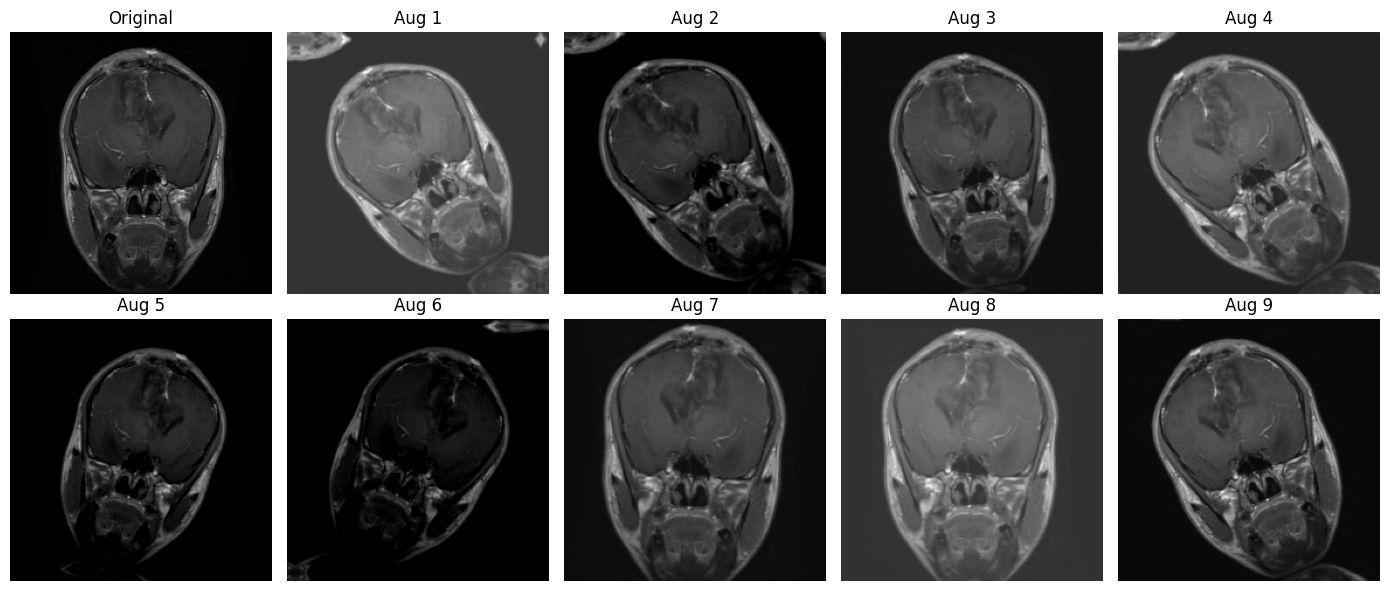

In [ ]:
#3.4 Visualizar el augmentation
sample_batch = next(iter(train_dataset))
sample_img = normalization(sample_batch[0][0:1])

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flat):
    img = sample_img[0] if i == 0 else data_augmentation(sample_img, training=True)[0]
    ax.imshow(np.clip(img.numpy(), 0, 1)); ax.axis("off")
    ax.set_title("Original" if i == 0 else f"Aug {i}")
plt.tight_layout(); plt.show()

## Fase 4: Diseño de 3 Modelos CNN

In [ ]:
#4.1 Modelo 1: CNN Baseline
def build_baseline_model(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.Conv2D(32, (3,3), padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Conv2D(64, (3,3), padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Conv2D(128, (3,3), padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ], name="cnn_baseline")
    return model

model_baseline = build_baseline_model((*IMG_SIZE, 3), NUM_CLASSES)
model_baseline.summary()

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 128,196 (500.77 KB)

 Trainable params: 127,748 (499.02 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
#4.2 Modelo 2: CNN con bloques residuales
def residual_block(x, filters, stride=1):
    shortcut = x
    x = tf.keras.layers.Conv2D(filters, (3,3), strides=stride, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Conv2D(filters, (3,3), padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = tf.keras.layers.Conv2D(filters, (1,1), strides=stride, padding="same")(shortcut)
        shortcut = tf.keras.layers.BatchNormalization()(shortcut)
    x = tf.keras.layers.Add()([x, shortcut])
    x = tf.keras.layers.Activation("relu")(x)
    return x

def build_improved_model(input_shape, num_classes):
    inputs = tf.keras.layers.Input(shape=input_shape)
    x = tf.keras.layers.Conv2D(64, (7,7), strides=2, padding="same")(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.MaxPooling2D((3,3), strides=2, padding="same")(x)
    x = residual_block(x, 64)
    x = residual_block(x, 64)
    x = residual_block(x, 128, stride=2)
    x = residual_block(x, 128)
    x = residual_block(x, 256, stride=2)
    x = residual_block(x, 256)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(512, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)
    return tf.keras.Model(inputs, outputs, name="cnn_improved")

model_improved = build_improved_model((*IMG_SIZE, 3), NUM_CLASSES)
model_improved.summary()

Model: "cnn_improved"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      9,472 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 56, 56,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     36,928 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │     36,928 │ activation_4[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 56, 56,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 56, 56,    │     36,928 │ activation_5[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 56, 56,    │     36,928 │ activation_6[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_7[0][0]  

 Total params: 2,925,188 (11.16 MB)

 Trainable params: 2,919,684 (11.14 MB)

 Non-trainable params: 5,504 (21.50 KB)

In [ ]:
#4.3 Modelo 3: CNN optimizada
def build_optimized_model(input_shape, num_classes):
    inputs = tf.keras.layers.Input(shape=input_shape)
    x = tf.keras.layers.RandomFlip("horizontal")(inputs)
    x = tf.keras.layers.RandomRotation(0.1)(x)
    x = tf.keras.layers.RandomZoom(0.1)(x)
    x = tf.keras.layers.Conv2D(64, (7,7), strides=2, padding="same",
                               kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.MaxPooling2D((3,3), strides=2, padding="same")(x)
    for filters in [64, 64, 128, 128, 256, 256]:
        stride = 2 if (filters != 64 and x.shape[-1] != filters) else 1
        x = residual_block(x, filters, stride)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(512, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(256, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)
    return tf.keras.Model(inputs, outputs, name="cnn_optimized")

model_optimized = build_optimized_model((*IMG_SIZE, 3), NUM_CLASSES)
model_optimized.summary()

Model: "cnn_optimized"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_1       │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_1   │ (None, 224, 224,  │          0 │ random_flip_1[0]… │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom_1       │ (None, 224, 224,  │          0 │ random_rotation_… │
│ (RandomZoom)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 112, 112,  │      9,472 │ random_zoom_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 56, 56,    │          0 │ activation_17[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 56, 56,    │     36,928 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_18       │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 56, 56,    │     36,928 │ activation_18[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_19       │ (None, 56, 56,    │          0 │ add_6[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 56, 56,    │     36,928 │ activation_19[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_21[0][0] 

 Total params: 3,055,492 (11.66 MB)

 Trainable params: 3,049,988 (11.63 MB)

 Non-trainable params: 5,504 (21.50 KB)

In [ ]:
#4.4 Comparar tamaños
print(f"{'Modelo':<25} {'Params':>12} {'Tamaño (MB)':>12}")
print("-" * 50)
for name, m in [("CNN Baseline", model_baseline), ("CNN Mejorada", model_improved), ("CNN Optimizada", model_optimized)]:
    p = m.count_params()
    print(f"{name:<25} {p:>12,} {p*4/1024/1024:>12.1f}")

Modelo                          Params  Tamaño (MB)
--------------------------------------------------
CNN Baseline                   128,196          0.5
CNN Mejorada                 2,925,188         11.2
CNN Optimizada               3,055,492         11.7


## Fase 5: Entrenamiento con Callbacks Profesionales

In [ ]:
#5.1 Configuración y función de entrenamiento
CONFIG = {
    "learning_rate": 1e-3,
    "epochs": 50,
    "batch_size": BATCH_SIZE,
    "weight_decay": 1e-4,
    "label_smoothing": 0.1,
}

def train_model(model, train_ds, val_ds, config, experiment_name):
    log_dir = f"logs/{experiment_name}"
    checkpoint_dir = f"checkpoints/{experiment_name}"
    os.makedirs(log_dir, exist_ok=True)
    os.makedirs(checkpoint_dir, exist_ok=True)
    with open(f"{log_dir}/config.json", "w") as f:
        json.dump(config, f, indent=2)

    optimizer = tf.keras.optimizers.Adam(learning_rate=config["learning_rate"],
                                         weight_decay=config["weight_decay"])
    loss_fn = tf.keras.losses.CategoricalCrossentropy(label_smoothing=config["label_smoothing"])
    model.compile(optimizer=optimizer, loss=loss_fn,
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(f"{checkpoint_dir}/best_model.keras",
            monitor="val_accuracy", mode="max", save_best_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
            restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
            patience=4, min_lr=1e-6, verbose=1),
        tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=0),
        tf.keras.callbacks.CSVLogger(f"{log_dir}/training_log.csv"),
    ]
    history = model.fit(train_ds, validation_data=val_ds,
                        epochs=config["epochs"], callbacks=callbacks, verbose=1)
    return history, log_dir, checkpoint_dir

print("Función de entrenamiento definida")

Función de entrenamiento definida


In [ ]:
#5.2 Entrenar el modelo 1 (Baseline)
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
history_baseline, log_baseline, ckpt_baseline = train_model(
    model_baseline, train_ds, val_ds, CONFIG, f"baseline_{timestamp}")

Epoch 1/50
134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step - accuracy: 0.4741 - auc: 0.7480 - loss: 1.2011
Epoch 1: val_accuracy improved from None to 0.26217, saving model to checkpoints/baseline_20261109_234626/best_model.keras

Epoch 1: finished saving model to checkpoints/baseline_20261109_234626/best_model.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 85s 498ms/step - accuracy: 0.5266 - auc: 0.7929 - loss: 1.1418 - val_accuracy: 0.2622 - val_auc: 0.5932 - val_loss: 2.1864 - learning_rate: 0.0010
Epoch 2/50
133/134 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step - accuracy: 0.5739 - auc: 0.8249 - loss: 1.0867
Epoch 2: val_accuracy improved from 0.26217 to 0.26311, saving model to checkpoints/baseline_20261109_234626/best_model.keras

Epoch 2: finished saving model to checkpoints/baseline_20261109_234626/best_model.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 56s 407ms/step - accuracy: 0.5909 - auc: 0.8352 - loss: 1.0664 - val_accuracy: 0.2631 - val_auc: 0.5874 - val_loss: 2.9827 - learning_rate: 0.0010
Epoch 3/50
133/13

In [ ]:
#5.3 Entrenar el modelo 2 (Mejorada)
history_improved, log_improved, ckpt_improved = train_model(
    model_improved, train_ds, val_ds, CONFIG, f"improved_{timestamp}")

Epoch 1/50
134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 574ms/step - accuracy: 0.5025 - auc: 0.7531 - loss: 1.3279
Epoch 1: val_accuracy improved from None to 0.09176, saving model to checkpoints/improved_20261109_234626/best_model.keras

Epoch 1: finished saving model to checkpoints/improved_20261109_234626/best_model.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 123s 654ms/step - accuracy: 0.5602 - auc: 0.8058 - loss: 1.2138 - val_accuracy: 0.0918 - val_auc: 0.3557 - val_loss: 3.3011 - learning_rate: 0.0010
Epoch 2/50
133/134 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step - accuracy: 0.5856 - auc: 0.8303 - loss: 1.1513
Epoch 2: val_accuracy improved from 0.09176 to 0.31929, saving model to checkpoints/improved_20261109_234626/best_model.keras

Epoch 2: finished saving model to checkpoints/improved_20261109_234626/best_model.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 85s 414ms/step - accuracy: 0.6081 - auc: 0.8454 - loss: 1.1138 - val_accuracy: 0.3193 - val_auc: 0.6479 - val_loss: 1.7090 - learning_rate: 0.0010
Epoch 3/50
133/1

In [ ]:
#5.4 Entrenar el modelo 3 (Optimizada, sin augmentation externo)
history_optimized, log_optimized, ckpt_optimized = train_model(
    model_optimized, train_ds_plain, val_ds, CONFIG, f"optimized_{timestamp}")

Epoch 1/50
134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.5917 - auc: 0.8289 - loss: 1.2133
Epoch 1: val_accuracy improved from None to 0.34831, saving model to checkpoints/optimized_20261109_234626/best_model.keras

Epoch 1: finished saving model to checkpoints/optimized_20261109_234626/best_model.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 42s 186ms/step - accuracy: 0.6632 - auc: 0.8779 - loss: 1.0760 - val_accuracy: 0.3483 - val_auc: 0.6714 - val_loss: 1.7102 - learning_rate: 0.0010
Epoch 2/50
133/134 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.7443 - auc: 0.9217 - loss: 0.9177
Epoch 2: val_accuracy improved from 0.34831 to 0.36891, saving model to checkpoints/optimized_20261109_234626/best_model.keras

Epoch 2: finished saving model to checkpoints/optimized_20261109_234626/best_model.keras
134/134 ━━━━━━━━━━━━━━━━━━━━ 23s 172ms/step - accuracy: 0.7594 - auc: 0.9273 - loss: 0.8987 - val_accuracy: 0.3689 - val_auc: 0.6930 - val_loss: 1.3560 - learning_rate: 0.0010
Epoch 3/50
13

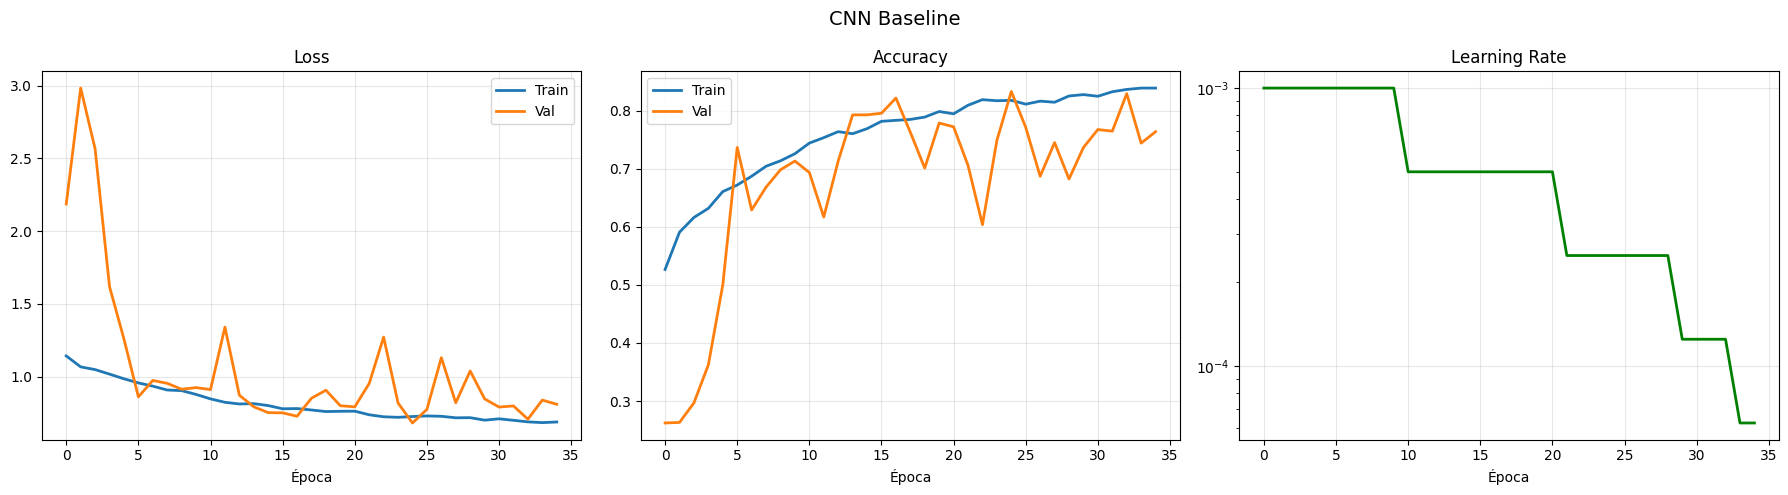

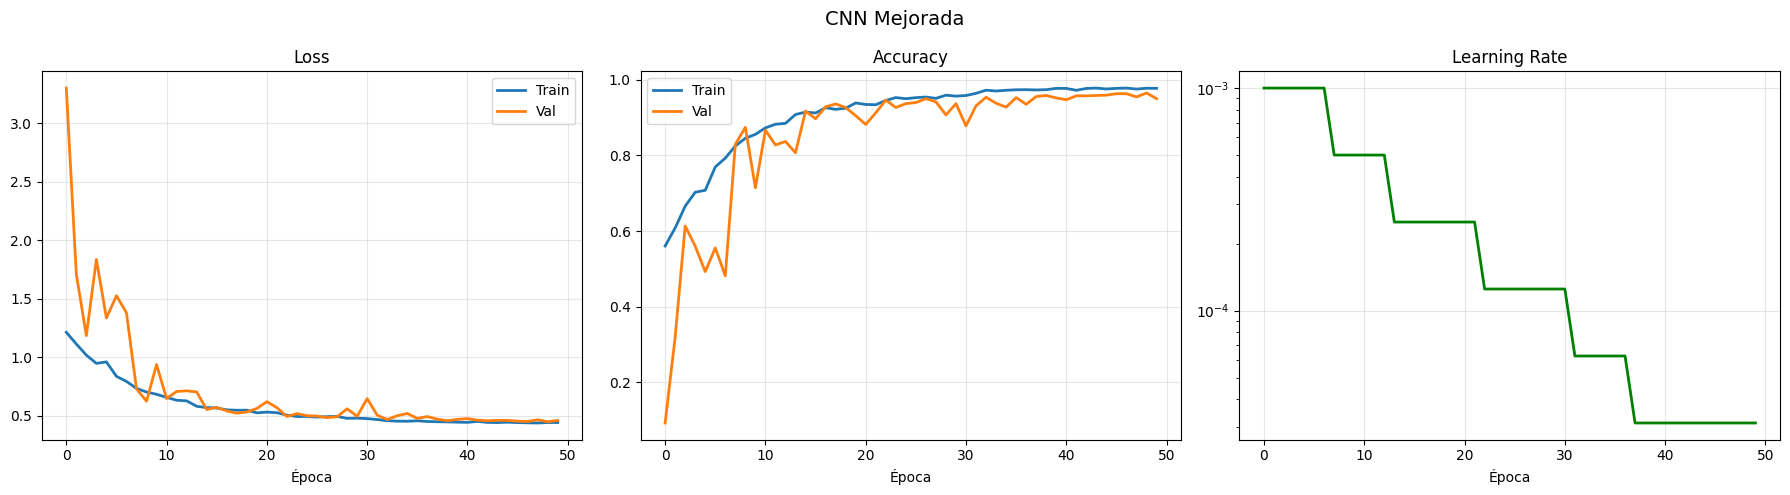

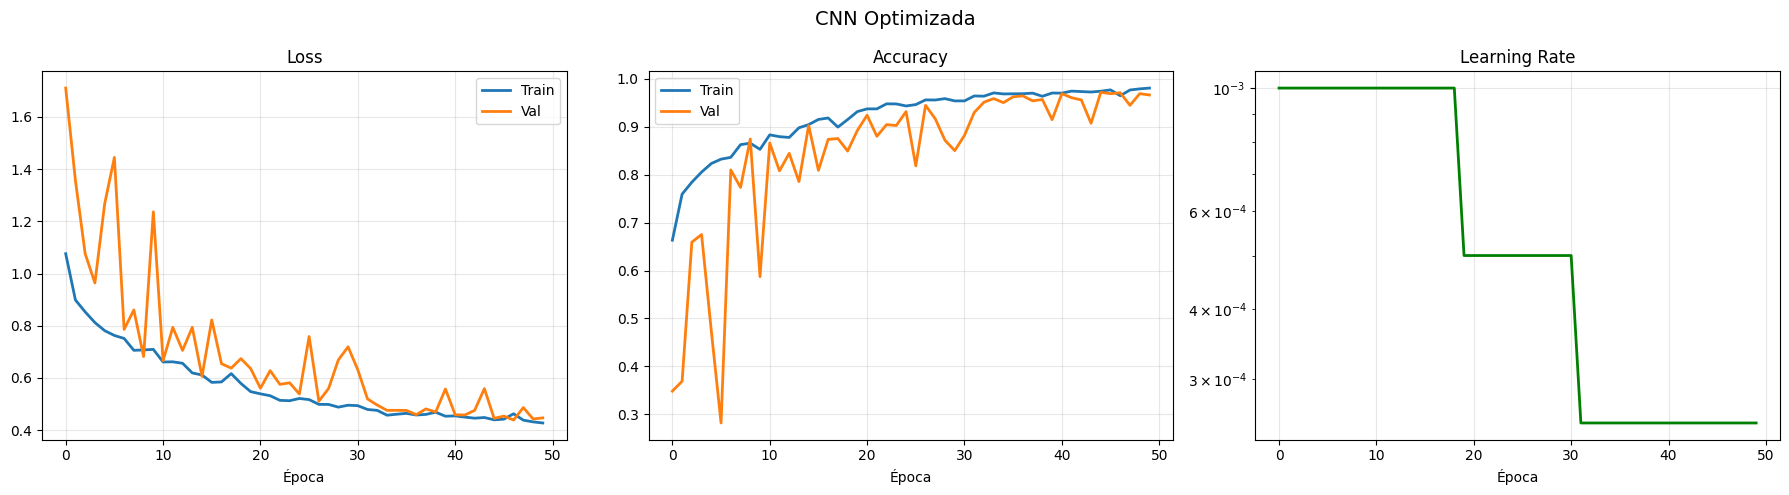

In [ ]:
#5.5 Curvas de aprendizaje
def plot_training_history(history, title="", save_path=None):
    h = history.history
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].plot(h["loss"], label="Train", linewidth=2); axes[0].plot(h["val_loss"], label="Val", linewidth=2)
    axes[0].set_title("Loss"); axes[0].set_xlabel("Época"); axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[1].plot(h["accuracy"], label="Train", linewidth=2); axes[1].plot(h["val_accuracy"], label="Val", linewidth=2)
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Época"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
    lr_key = next((k for k in ("lr", "learning_rate") if k in h), None)
    if lr_key:
        axes[2].plot(h[lr_key], linewidth=2, color="green")
        axes[2].set_title("Learning Rate"); axes[2].set_xlabel("Época")
        axes[2].set_yscale("log"); axes[2].grid(True, alpha=0.3)
    plt.suptitle(title, fontsize=14); plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

for name, hist, log_dir in [("CNN Baseline", history_baseline, log_baseline),
                            ("CNN Mejorada", history_improved, log_improved),
                            ("CNN Optimizada", history_optimized, log_optimized)]:
    plot_training_history(hist, title=name, save_path=f"{log_dir}/training_curves.png")

### Pregunta de análisis
Observa las curvas de los 3 modelos. ¿Cuál muestra mejor ajuste? ¿Alguno presenta overfitting (train mucho mayor que val)?

**Análisis:**
- **CNN Baseline:** se detuvo por EarlyStopping en la época 35 y su mejor punto fue la época 25 (val accuracy 0.833, val loss 0.681). Train quedó en torno a 0.84, y la curva de validación es muy irregular (por ejemplo, 0.83 en la época 25 y 0.60 en la 23). No hay overfitting: train y validación están parecidos y bajos. Es un problema de capacidad insuficiente (underfitting) y de inestabilidad.
- **CNN Mejorada:** corrió las 50 épocas. Train llegó a 0.978 y validación a 0.95–0.965 (mejor val accuracy 0.965 en la época 49, val loss 0.449). La brecha train–validación es de unos 1.5 a 3 puntos, es decir leve. El learning rate bajó 5 veces hasta 3.1e-5 y el modelo seguía mejorando al final, así que el límite de 50 épocas cortó antes de que se estancara.
- **CNN Optimizada:** también corrió las 50 épocas. Train 0.981, validación 0.966–0.972 (mejor val accuracy 0.972 en la época 45 y mejor val loss 0.439 en la 47). Su curva de validación es la más estable y el learning rate bajó solo dos veces (hasta 2.5e-4).
- **Mejor ajuste:** la Optimizada, por menor val loss y mayor val accuracy, aunque su ventaja sobre la Mejorada es pequeña (unos 0.6 puntos).
- **Overfitting:** ninguno de los tres lo muestra de forma marcada. Hay que recordar que la exactitud de train se mide con augmentation y dropout activos, que la hacen algo menor de lo normal.
- **Ojo:** la validación sale de la misma fuente que train (0.972 en la Optimizada), pero en Testing la exactitud baja a 0.926. Esa diferencia no es overfitting a train: indica que Testing se parece menos a Training (ver la Fase 7).

## Fase 6: Suite de Evaluación Completa (conjunto Testing)

In [ ]:
#6.1 Elegir el mejor modelo (por validación) y predecir en Testing
histories = {
    "CNN Baseline":   (model_baseline,  history_baseline,  log_baseline,  ckpt_baseline),
    "CNN Mejorada":   (model_improved,  history_improved,  log_improved,  ckpt_improved),
    "CNN Optimizada": (model_optimized, history_optimized, log_optimized, ckpt_optimized),
}
best_name = max(histories, key=lambda n: max(histories[n][1].history["val_accuracy"]))
model, history_best, log_best, ckpt_best = histories[best_name]
print("Mejor modelo según validación:", best_name)

y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
print(f"Predicciones: {len(y_pred)}  |  Exactitud en Testing: {np.mean(y_pred == y_true):.4f}")

Mejor modelo según validación: CNN Optimizada
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step
Predicciones: 1600  |  Exactitud en Testing: 0.9256


In [ ]:
#6.2 Classification report
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

              precision    recall  f1-score   support

      glioma     0.9726    0.8000    0.8779       400
  meningioma     0.9409    0.9150    0.9278       400
     notumor     0.8386    1.0000    0.9122       400
   pituitary     0.9753    0.9875    0.9814       400

    accuracy                         0.9256      1600
   macro avg     0.9319    0.9256    0.9248      1600
weighted avg     0.9319    0.9256    0.9248      1600



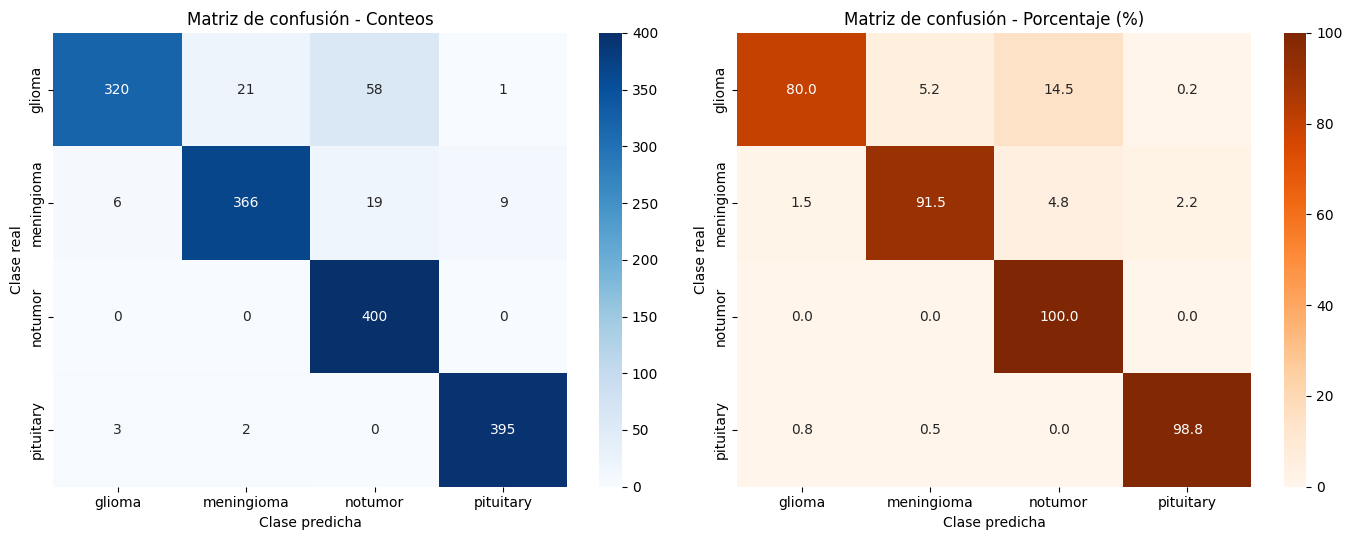

In [ ]:
#6.3 Matriz de confusión
def plot_confusion_matrix(y_true, y_pred, class_names, save_path=None):
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title("Matriz de confusión - Conteos"); axes[0].set_ylabel("Clase real"); axes[0].set_xlabel("Clase predicha")
    sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Oranges", xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title("Matriz de confusión - Porcentaje (%)"); axes[1].set_ylabel("Clase real"); axes[1].set_xlabel("Clase predicha")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

plot_confusion_matrix(y_true, y_pred, class_names, f"{log_best}/confusion_matrix.png")

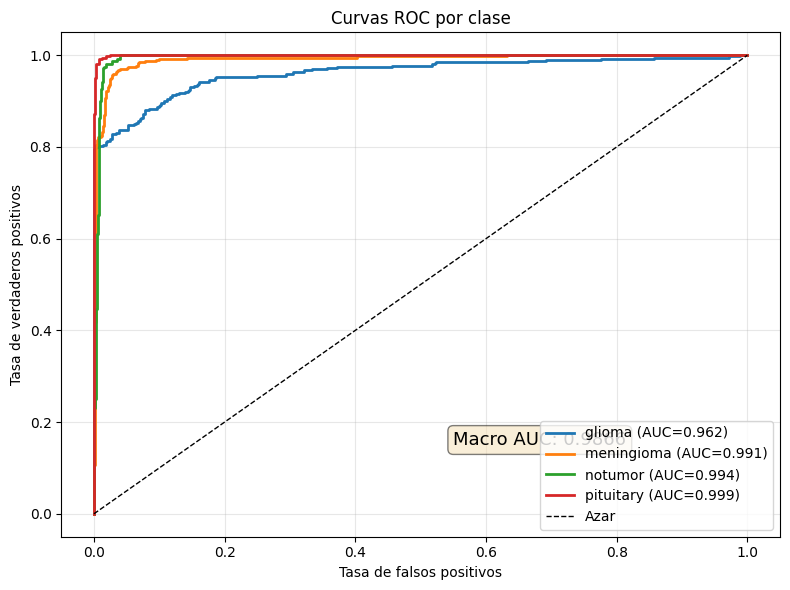

Macro AUC: 0.9866


In [ ]:
#6.4 Curvas ROC
def plot_roc_curves(y_true, y_pred_probs, class_names, save_path=None):
    n_classes = len(class_names)
    y_true_bin = label_binarize(y_true, classes=range(n_classes))
    fig, ax = plt.subplots(figsize=(8, 6))
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
        ax.plot(fpr, tpr, linewidth=2, label=f"{class_names[i]} (AUC={auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Azar")
    ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
    ax.set_title("Curvas ROC por clase"); ax.legend(loc="lower right"); ax.grid(True, alpha=0.3)
    macro_auc = roc_auc_score(y_true_bin, y_pred_probs, multi_class="ovr", average="macro")
    ax.text(0.55, 0.15, f"Macro AUC: {macro_auc:.4f}", fontsize=13,
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    return macro_auc

macro_auc = plot_roc_curves(y_true, y_pred_probs, class_names, f"{log_best}/roc_curves.png")
print(f"Macro AUC: {macro_auc:.4f}")

## Fase 7: Análisis de Errores

In [ ]:
#7.1 Pares de clases más confundidos
def analyze_top_errors(y_true, y_pred, class_names, top_k=10):
    cm = confusion_matrix(y_true, y_pred)
    np.fill_diagonal(cm, 0)
    errors = [{"real": class_names[i], "predicha": class_names[j], "count": int(cm[i, j])}
              for i in range(len(class_names)) for j in range(len(class_names)) if cm[i, j] > 0]
    errors.sort(key=lambda x: x["count"], reverse=True)
    print(f"{'Real':<14} {'Predicha':<14} {'Errores':>8}")
    print("=" * 38)
    for err in errors[:top_k]:
        print(f"{err['real']:<14} {err['predicha']:<14} {err['count']:>8}")
    return errors[:top_k]

top_errors = analyze_top_errors(y_true, y_pred, class_names)

Real           Predicha        Errores
glioma         notumor              58
glioma         meningioma           21
meningioma     notumor              19
meningioma     pituitary             9
meningioma     glioma                6
pituitary      glioma                3
pituitary      meningioma            2
glioma         pituitary             1


Errores: 119 de 1600


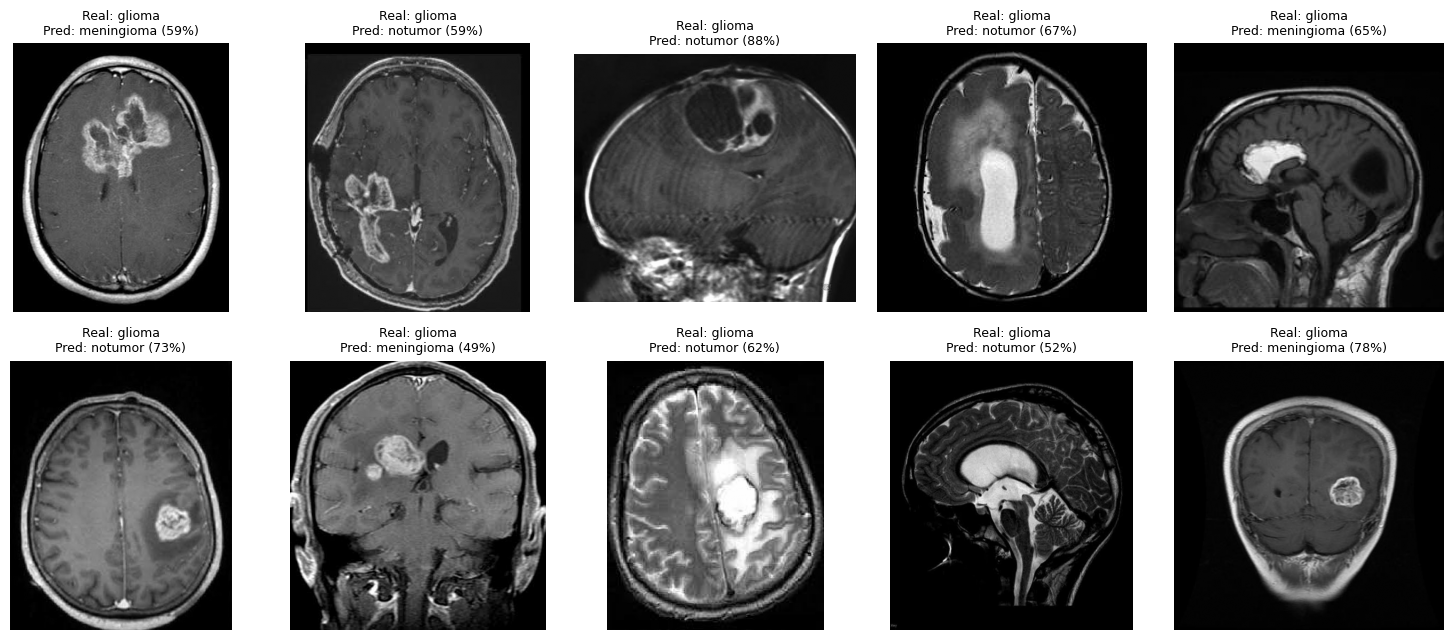

In [ ]:
#7.2 Imágenes mal clasificadas
paths = test_dataset.file_paths
idx_err = np.where(y_pred != y_true)[0]
print(f"Errores: {len(idx_err)} de {len(y_true)}")

fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, idx_err[:10]):
    ax.imshow(Image.open(paths[i]).convert("L"), cmap="gray")
    ax.set_title(f"Real: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]} ({y_pred_probs[i].max():.0%})", fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
#7.3 Exactitud por subgrupo (¿acierta igual en todos los tipos de imagen?)
df_pred = pd.DataFrame({"ruta": [os.path.normpath(p) for p in paths],
                        "real": [class_names[i] for i in y_true],
                        "pred": [class_names[i] for i in y_pred]})
df_pred["acierto"] = df_pred["real"] == df_pred["pred"]
df_meta["ruta_n"] = df_meta["ruta"].apply(os.path.normpath)
df_sub = df_pred.merge(df_meta[["ruta_n", "es_512", "es_gris"]], left_on="ruta", right_on="ruta_n")

print("Exactitud por clase y tamaño 512x512:")
display(df_sub.groupby(["real", "es_512"])["acierto"].agg(["mean", "count"]).round(3).unstack())
print("Exactitud por clase y escala de grises:")
display(df_sub.groupby(["real", "es_gris"])["acierto"].agg(["mean", "count"]).round(3).unstack())

Exactitud por clase y tamaño 512x512:


mean        count      
es_512      False  True  False True 
real                                
glioma      0.026  0.981    76   324
meningioma  0.855  0.940   117   283
notumor     1.000  1.000   397     3
pituitary   1.000  0.987     8   392

Exactitud por clase y escala de grises:


mean        count      
es_gris     False  True  False True 
real                                
glioma      0.557  0.987   174   226
meningioma  0.878  0.974   246   154
notumor     1.000  1.000   394     6
pituitary   0.987  0.988    77   323

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_79']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


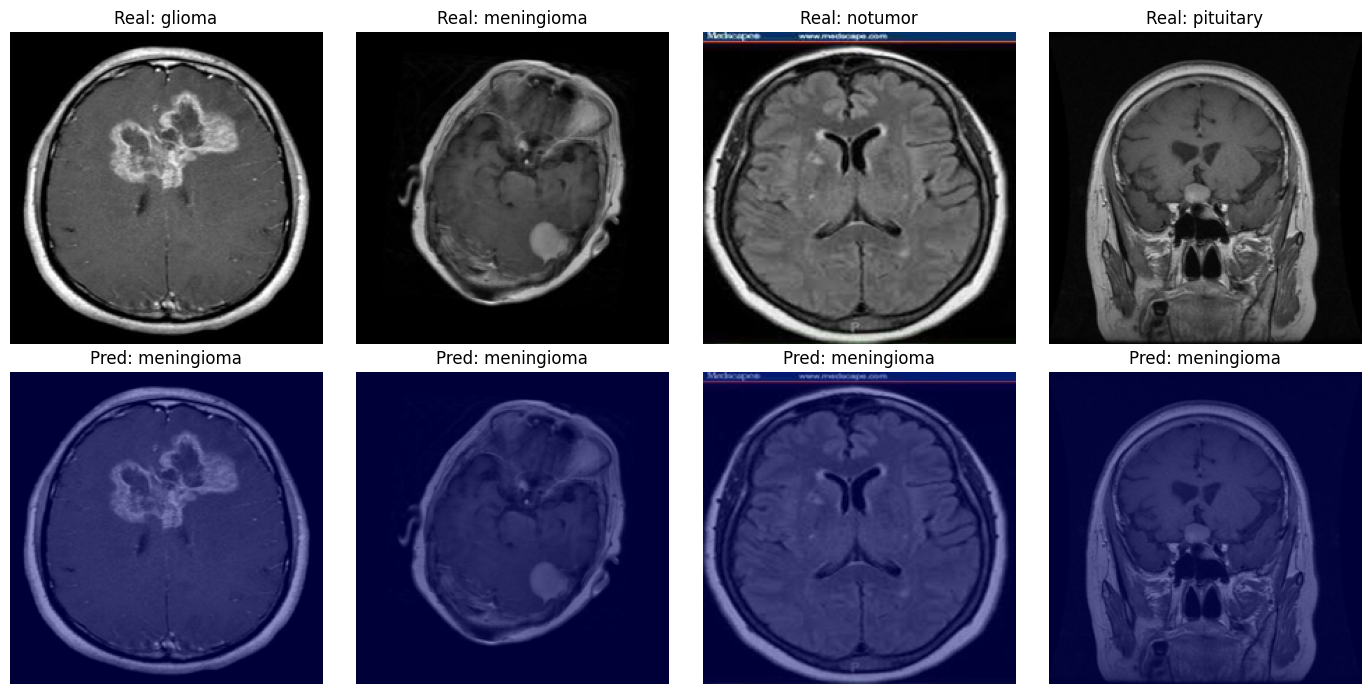

In [ ]:
#7.4 Grad-CAM (opcional): ¿en qué zona mira el modelo?
def make_gradcam(model, img_array, layer_name):
    grad_model = tf.keras.Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array)
        class_idx = tf.argmax(preds[0])
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.reduce_sum(conv_out[0] * weights, axis=-1)
    cam = tf.nn.relu(cam) / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), int(class_idx)

last_conv = [l.name for l in model.layers if len(l.output.shape) == 4][-1]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for j, c in enumerate(class_names):
    i = int(np.where(y_true == j)[0][0])
    img = np.asarray(Image.open(paths[i]).convert("RGB").resize(IMG_SIZE), dtype=np.float32) / 255.0
    cam, k = make_gradcam(model, img[None], last_conv)
    cam = tf.image.resize(cam[..., None], IMG_SIZE).numpy()[..., 0]
    axes[0, j].imshow(img); axes[0, j].set_title(f"Real: {c}"); axes[0, j].axis("off")
    axes[1, j].imshow(img); axes[1, j].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, j].set_title(f"Pred: {class_names[k]}"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

### Tabla de mejoras
| Hallazgo | Acción correctiva propuesta |
|---|---|
| Par de clases más confundido: glioma predicho como notumor (58 errores; sumando glioma→meningioma son 80 de los 119 errores totales) | Reunir o balancear más ejemplos de glioma de distintas fuentes y tamaños, aplicar augmentation de escala y resolución para que el modelo no use el tamaño de la imagen como pista, y vigilar el recall de glioma (0.80) por ser un falso negativo costoso |
| Subgrupo con peor exactitud: glioma en imágenes que no son 512x512 (2.6% de acierto con 76 imágenes, frente a 98.1% en las 324 de 512x512) | Rehacer la partición mezclando las fuentes para que Testing no contenga subgrupos ausentes en Training, y reportar siempre la exactitud por subgrupo además de la global |
| Zona que mira el modelo (Grad-CAM): no concluyente. El mapa salió uniforme, sin zonas resaltadas, y las 4 predicciones fueron meningioma aunque notumor tiene recall 1.000, por lo que esa celda no es confiable | Repetir el Grad-CAM forzando el modo de inferencia, con un modelo sin capas aleatorias y sobre varias imágenes, incluidos los errores glioma→notumor. Si el calor cae fuera del tumor, se confirma el sesgo de captura |

## Fase 8: Comparación Sistemática de Modelos

In [ ]:
#8.1 Tabla comparativa (incluye exactitud en Testing)
results = []
for name, (m, hist, _, _) in histories.items():
    test_loss, test_acc, test_auc = m.evaluate(test_ds, verbose=0)
    params = m.count_params()
    results.append({
        "Modelo": name,
        "Val Accuracy": f"{max(hist.history['val_accuracy']):.4f}",
        "Val Loss": f"{min(hist.history['val_loss']):.4f}",
        "Test Accuracy": f"{test_acc:.4f}",
        "Test AUC": f"{test_auc:.4f}",
        "Parámetros": f"{params:,}",
        "Épocas": len(hist.history["loss"]),
        "Tamaño (MB)": f"{params*4/1024/1024:.1f}",
    })
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))


        Modelo Val Accuracy Val Loss Test Accuracy Test AUC Parámetros  Épocas Tamaño (MB)
  CNN Baseline       0.8333   0.6807        0.7725   0.9263    128,196      35         0.5
  CNN Mejorada       0.9654   0.4489        0.9344   0.9822  2,925,188      50        11.2
CNN Optimizada       0.9719   0.4391        0.9269   0.9862  3,055,492      50        11.7


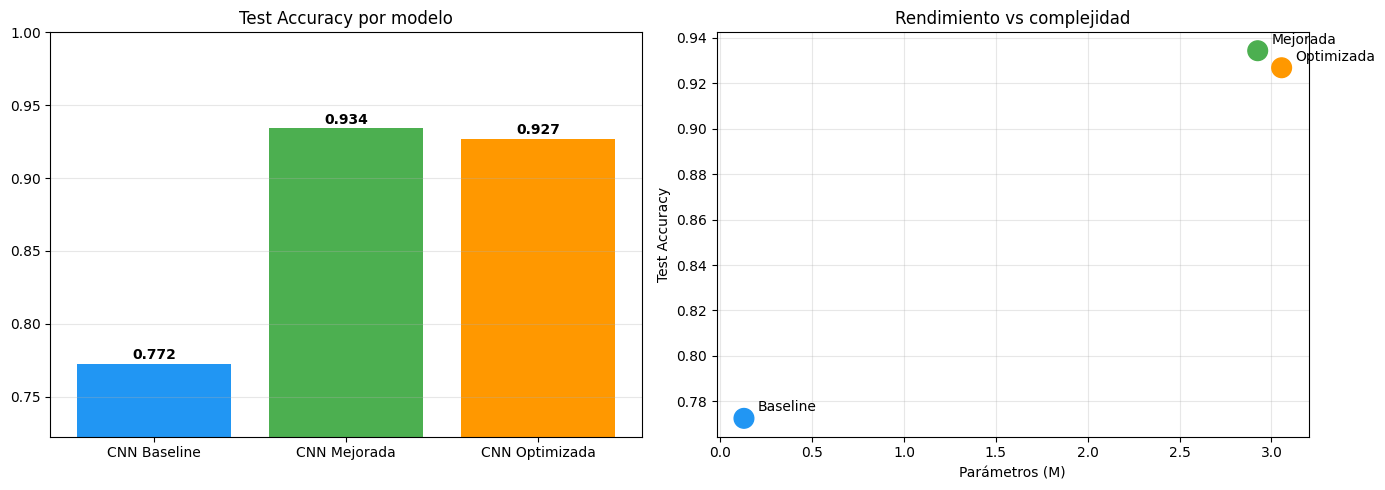

In [ ]:
#8.2 Gráfico comparativo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
model_names = [r["Modelo"] for r in results]
accuracies = [float(r["Test Accuracy"]) for r in results]
params_m = [int(r["Parámetros"].replace(",", "")) / 1e6 for r in results]
colors = ["#2196F3", "#4CAF50", "#FF9800"]

axes[0].bar(model_names, accuracies, color=colors)
axes[0].set_title("Test Accuracy por modelo")
axes[0].set_ylim([max(0, min(accuracies) - 0.05), 1.0]); axes[0].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(accuracies):
    axes[0].text(i, v + 0.003, f"{v:.3f}", ha="center", fontweight="bold")

axes[1].scatter(params_m, accuracies, s=200, c=colors, zorder=5)
for i, n in enumerate(model_names):
    axes[1].annotate(n.replace("CNN ", ""), (params_m[i], accuracies[i]), textcoords="offset points", xytext=(10, 5))
axes[1].set_xlabel("Parámetros (M)"); axes[1].set_ylabel("Test Accuracy")
axes[1].set_title("Rendimiento vs complejidad"); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{log_best}/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Pregunta de producción
¿Qué modelo elegirías si el requisito es menos de 10 MB para móvil? Justifica con números de la tabla.

**Respuesta:** elegiría la **CNN Optimizada convertida a TFLite en float16**.
- Como modelo Keras, solo la Baseline cumple los 10 MB (0.5 MB), pero su exactitud en Testing es 0.7725, unos 15 puntos menos que las otras (0.9344 y 0.9269) y con menor AUC (0.9263). No sirve para el objetivo.
- La Mejorada (11.2 MB) y la Optimizada (11.7 MB) exceden el límite en esa forma. Pero la conversión a TFLite float16 que se hizo en la Fase 12 deja la Optimizada en **5.8 MB** (frente a 11.6 MB en float32 y 35.2 MB del .keras, que incluye el estado del optimizador), por debajo de 10 MB.
- Entre las dos, la Optimizada tiene mejor validación (val accuracy 0.9719 y val loss 0.4391, contra 0.9654 y 0.4489) y el mayor AUC en Testing (0.9862). La Mejorada saca 0.9344 contra 0.9269 en exactitud de Testing, una diferencia de unas 12 imágenes de 1,600 que no es concluyente. Elegí según validación para no decidir con Testing.
- Pendiente: no se midió la exactitud del archivo TFLite float16 en Testing. Habría que comprobar que no pierde precisión antes de usarlo.

## Fases 9-11: Versionado, Logging y Documentación

In [ ]:
#9.1 Metadata del modelo
def save_model_metadata(model, history, config, dataset_info, save_path):
    metadata = {
        "version": "1.0",
        "timestamp": datetime.datetime.now().isoformat(),
        "model": {
            "architecture": model.name,
            "total_params": model.count_params(),
            "input_shape": list(model.input.shape[1:]),
            "output_classes": int(model.output.shape[-1]),
        },
        "training": {
            "config": config,
            "best_val_accuracy": float(max(history.history["val_accuracy"])),
            "best_val_loss": float(min(history.history["val_loss"])),
            "final_epoch": len(history.history["loss"]),
        },
        "dataset": dataset_info,
        "environment": {
            "tensorflow": tf.__version__,
            "python": platform.python_version(),
            "gpu": str(tf.config.list_physical_devices("GPU")),
        },
    }
    with open(save_path, "w") as f:
        json.dump(metadata, f, indent=2, default=str)
    print("Metadata guardada:", save_path)
    return metadata

test_acc_best = float(np.mean(y_pred == y_true))
metadata = save_model_metadata(
    model, history_best, CONFIG,
    {"name": "Brain Tumor MRI (Kaggle, masoudnickparvar)", "classes": class_names,
     "train": int(df_split.loc["TOTAL", "train"]), "val": int(df_split.loc["TOTAL", "val"]),
     "test": int(df_split.loc["TOTAL", "test"]), "test_accuracy": test_acc_best},
    f"{ckpt_best}/metadata.json")
print(json.dumps(metadata, indent=2, default=str))

Metadata guardada: checkpoints/optimized_20261109_234626/metadata.json
{
  "version": "1.0",
  "timestamp": "2026-11-10T01:39:12.076462",
  "model": {
    "architecture": "cnn_optimized",
    "total_params": 3055492,
    "input_shape": [
      224,
      224,
      3
    ],
    "output_classes": 4
  },
  "training": {
    "config": {
      "learning_rate": 0.001,
      "epochs": 50,
      "batch_size": 32,
      "weight_decay": 0.0001,
      "label_smoothing": 0.1
    },
    "best_val_accuracy": 0.9719101190567017,
    "best_val_loss": 0.4391292631626129,
    "final_epoch": 50
  },
  "dataset": {
    "name": "Brain Tumor MRI (Kaggle, masoudnickparvar)",
    "classes": [
      "glioma",
      "meningioma",
      "notumor",
      "pituitary"
    ],
    "train": 4261,
    "val": 1068,
    "test": 1600,
    "test_accuracy": 0.925625
  },
  "environment": {
    "tensorflow": "2.21.0",
    "python": "3.13.16",
    "gpu": "[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]"
  

In [ ]:
#9.2 Ficha del modelo (model card)
model_card = f"""# Model Card: {best_name} (v1.0)

**Tarea:** clasificación de MRI cerebral en {NUM_CLASSES} clases ({', '.join(class_names)}).
**Datos:** Brain Tumor MRI (Kaggle). Train {int(df_split.loc['TOTAL','train'])}, val {int(df_split.loc['TOTAL','val'])}, test {int(df_split.loc['TOTAL','test'])}.
**Preprocesamiento:** duplicados exactos y imágenes "aug" quitados de Training; RGB, {IMG_SIZE[0]}x{IMG_SIZE[1]}, escala 1/255.
**Resultado en Testing:** exactitud {test_acc_best:.4f}, macro AUC {macro_auc:.4f}.

## Limitaciones
- Las clases difieren en tamaño, color y brillo de las imágenes (sesgo de adquisición): el resultado puede ser optimista.
- Proyecto académico: no sustituye un diagnóstico médico.
"""
with open(f"{ckpt_best}/MODEL_CARD.md", "w", encoding="utf-8") as f:
    f.write(model_card)
print(model_card)

# Model Card: CNN Optimizada (v1.0)

**Tarea:** clasificación de MRI cerebral en 4 clases (glioma, meningioma, notumor, pituitary).
**Datos:** Brain Tumor MRI (Kaggle). Train 4261, val 1068, test 1600.
**Preprocesamiento:** duplicados exactos y imágenes "aug" quitados de Training; RGB, 224x224, escala 1/255.
**Resultado en Testing:** exactitud 0.9256, macro AUC 0.9866.

## Limitaciones
- Las clases difieren en tamaño, color y brillo de las imágenes (sesgo de adquisición): el resultado puede ser optimista.
- Proyecto académico: no sustituye un diagnóstico médico.



## Fase 12: Despliegue Básico

In [ ]:
#12.1 Guardar y verificar el modelo final
os.makedirs("models/production", exist_ok=True)
model.save("models/production/model_v1.keras")
print("Modelo guardado: models/production/model_v1.keras")

loaded_model = tf.keras.models.load_model("models/production/model_v1.keras")
test_loss, test_acc, test_auc = loaded_model.evaluate(test_ds, verbose=0)
print(f"Modelo cargado - Test accuracy: {test_acc:.4f}, Test AUC: {test_auc:.4f}")

Modelo guardado: models/production/model_v1.keras
Modelo cargado - Test accuracy: 0.9269, Test AUC: 0.9862


In [ ]:
#12.2 Conversión a TFLite
def convert_to_tflite(keras_path, output_path, quantize=False):
    m = tf.keras.models.load_model(keras_path)
    converter = tf.lite.TFLiteConverter.from_keras_model(m)
    if quantize:
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
    tflite_model = converter.convert()
    with open(output_path, "wb") as f:
        f.write(tflite_model)
    orig_size = os.path.getsize(keras_path) / (1024 * 1024)
    lite_size = os.path.getsize(output_path) / (1024 * 1024)
    print(f"Original: {orig_size:.1f} MB -> TFLite: {lite_size:.1f} MB ({(1 - lite_size/orig_size)*100:.0f}% reducción)")
    return lite_size

convert_to_tflite("models/production/model_v1.keras", "models/production/model_v1.tflite")
convert_to_tflite("models/production/model_v1.keras", "models/production/model_v1_q.tflite", quantize=True)

Saved artifact at '/tmp/tmpm307_5fd'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  136085802519248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136085802523472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136085802521360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136085802521744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136085802523856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136085802523280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136085802523088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136085802522896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136085801891984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136085801893328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1360858018916

5.835247039794922

Predicción: meningioma (61.7%)
  meningioma: 61.7%
  notumor: 23.3%
  glioma: 8.7%


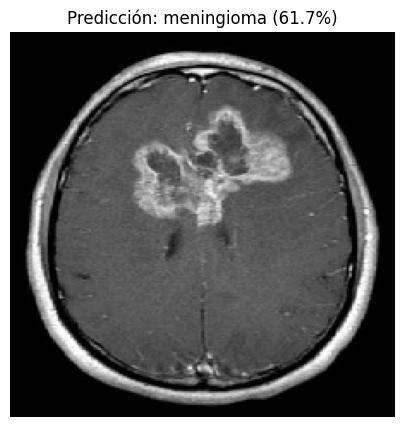

('meningioma', np.float32(0.6172774))

In [ ]:
#12.3 Script de predicción
def predict_image(model_path, image_path, class_names, img_size=(224, 224)):
    m = tf.keras.models.load_model(model_path)
    img = tf.keras.utils.load_img(image_path, target_size=img_size)
    arr = np.expand_dims(tf.keras.utils.img_to_array(img) / 255.0, axis=0)
    preds = m.predict(arr, verbose=0)
    predicted = class_names[np.argmax(preds[0])]
    conf = np.max(preds[0])
    print(f"Predicción: {predicted} ({conf:.1%})")
    for idx in np.argsort(preds[0])[-3:][::-1]:
        print(f"  {class_names[idx]}: {preds[0][idx]:.1%}")
    plt.figure(figsize=(5, 5)); plt.imshow(img); plt.axis("off")
    plt.title(f"Predicción: {predicted} ({conf:.1%})"); plt.show()
    return predicted, conf

sample_dir = os.path.join(TEST_DIR, class_names[0])
sample_path = os.path.join(sample_dir, sorted(os.listdir(sample_dir))[0])
predict_image("models/production/model_v1.keras", sample_path, class_names)

In [ ]:
#12.4 Descargar los resultados (Colab borra los archivos al cerrar la sesión)
from google.colab import files
os.makedirs("entregable", exist_ok=True)
shutil.copytree("models/production", "entregable/models", dirs_exist_ok=True)
shutil.copytree("logs", "entregable/logs", dirs_exist_ok=True)
shutil.copytree(ckpt_best, "entregable/checkpoint_mejor_modelo", dirs_exist_ok=True)
shutil.make_archive("resultados_proyecto", "zip", "entregable")
files.download("resultados_proyecto.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Checklist del pipeline completo
| # | Fase | Estado |
|---|---|---|
| 1 | Definición del problema | ✅ |
| 2 | Selección del dataset + EDA | ✅ |
| 3 | Preprocesamiento y augmentation | ✅ |
| 4 | Diseño de 3 modelos | ✅ |
| 5 | Entrenamiento con callbacks | ✅ |
| 6 | Evaluación (Testing) | ✅ |
| 7 | Análisis de errores | ✅ (Grad-CAM no concluyente) |
| 8 | Comparación de modelos | ✅ |
| 9-11 | Versionado, logging y documentación | ✅ |
| 12 | Despliegue (Keras + TFLite) | ✅ |

## Conclusiones finales

**Resultados.** El mejor modelo según validación fue la CNN Optimizada: exactitud 0.9256 en Testing (classification report), macro AUC 0.9866 y F1 macro 0.9248. La CNN Mejorada obtuvo 0.9344 y la Baseline 0.7725. Pasar de la Baseline a un modelo con bloques residuales sube unos 16 puntos; los añadidos de la Optimizada no dan una mejora clara sobre la Mejorada.

**Errores.** Hubo 119 errores en 1,600 imágenes y 80 son gliomas (recall 0.80). El más grave es glioma predicho como "sin tumor" (58 casos), un falso negativo, con tumores visibles clasificados como notumor con hasta 88% de confianza. Notumor tiene recall 1.00 pero precisión 0.84, porque el modelo tiende a asignar esa clase de más.

**Sesgo de captura.** El EDA ya mostraba que solo con metadatos se acierta 0.614 (azar 0.25). El análisis por subgrupo lo confirma: los gliomas que no son 512x512 se aciertan solo el 2.6% de las veces, frente a 98.1% en los 512x512. El modelo parece haber aprendido que una imagen de tamaño distinto es "sin tumor", y por eso falla donde Testing difiere de Training: según mis cálculos con tu df_meta, los gliomas de Training son 100% de 512x512 y los de Testing solo 81%. Por eso la exactitud baja de 0.972 en validación a 0.926 en Testing, y el rendimiento con datos de otra fuente probablemente sea menor.

**Despliegue.** El modelo se guardó (model_v1.keras, 35.2 MB) y se convirtió a TFLite: 11.6 MB en float32 y 5.8 MB en float16. La predicción de prueba sobre la primera imagen de glioma de Testing falló (meningioma, 61.7%), coherente con el análisis de errores.

**Limitaciones.** Sesgo de adquisición; Testing conserva 16 duplicados y 103 imágenes aug; la validación comparte fuente con Training; Grad-CAM no fue concluyente; no se midió la exactitud del TFLite. No sustituye un diagnóstico médico.

**Mejoras futuras.** Rehacer las particiones mezclando fuentes y tamaños, augmentation de escala y resolución, ponderar clases o priorizar el recall de glioma, transfer learning con una red preentrenada, más épocas para la Mejorada (seguía mejorando) y repetir el Grad-CAM.